# 03 — Régression linéaire multiple, multicolinéarité et régularisation

**Objectif** : battre la baseline « prix au m² de la commune » (MAE 31 336 €) que la régression simple n'avait pas battue.

Progression :
1. **Modèle A** — régression multiple sur le prix : surface, pièces, dépendance, année, département
2. **Diagnostic** de multicolinéarité (VIF)
3. **Modèle B** — même modèle sur le **logarithme du prix** (effets en %)
4. **Modèle C** — localisation fine : une variable par commune
5. **Ridge et Lasso** : la régularisation améliore-t-elle le modèle C ?
6. Comparaison finale et analyse des erreurs

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.linear_model import Lasso, LassoCV, LinearRegression, Ridge, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", "{:,.3f}".format)

BLEU = "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e8e7e2",
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
})

## 1. Données, découpage temporel et points de référence

In [2]:
apparts = pd.read_parquet(Path("..") / "data" / "processed" / "apparts.parquet").sort_values("date")
train = apparts[apparts["annee"] <= 2024]
test = apparts[apparts["annee"] == 2025]
y_train_log = np.log(train["prix"])
print(f"Apprentissage 2021-2024 : {len(train):,} ventes | Test 2025 : {len(test):,} ventes")


def evaluer(nom, y_predit):
    return {
        "modèle": nom,
        "MAE (€)": mean_absolute_error(test["prix"], y_predit),
        "RMSE (€)": mean_squared_error(test["prix"], y_predit) ** 0.5,
        "R²": r2_score(test["prix"], y_predit),
    }


resultats = []
predictions = {}

# Rappel du notebook 02 : baseline par commune et régression simple
prix_m2_train = train["prix"] / train["surface"]
ventes_par_commune = train["code_commune"].value_counts()
m2_commune = prix_m2_train.groupby(train["code_commune"]).median()[ventes_par_commune[ventes_par_commune >= 10].index]
m2_departement = prix_m2_train.groupby(train["code_departement"]).median()
m2_test = test["code_commune"].map(m2_commune).fillna(test["code_departement"].map(m2_departement))
resultats.append(evaluer("Baseline : prix au m² de la commune", m2_test * test["surface"]))

simple = LinearRegression().fit(train[["surface"]], train["prix"])
predictions["Régression simple"] = simple.predict(test[["surface"]])
resultats.append(evaluer("Régression simple : prix ~ surface", predictions["Régression simple"]))
pd.DataFrame(resultats).set_index("modèle")

Apprentissage 2021-2024 : 32,235 ventes | Test 2025 : 7,582 ventes


,MAE (€),RMSE (€),R²
modèle,,,
Baseline : prix au m² de la commune,"31,335.983","46,522.664",0.583
Régression simple : prix ~ surface,"38,985.047","54,938.231",0.419


## 2. Modèle A — régression multiple sur le prix

$$\text{prix} = \beta_0 + \beta_1\,\text{surface} + \beta_2\,\text{pièces} + \beta_3\,\text{dépendance} + \beta_4\,\text{année} + \sum_d \gamma_d\,\mathbb{1}[\text{département} = d]$$

- Le département est une variable **catégorielle** : on la transforme en indicatrices (*one-hot encoding*).
  On retire une modalité, le **Cher (18)**, qui sert de référence : sinon les indicatrices plus la constante seraient
  parfaitement colinéaires.
- `annee` est comptée à partir de 2021 (0 = 2021) : son coefficient est une tendance par an.

In [3]:
def variables_base(df):
    return pd.DataFrame({
        "surface": df["surface"],
        "pieces": df["pieces"],
        "a_dependance": df["a_dependance"].astype(int),
        "annee": df["annee"] - 2021,
    }, index=df.index)


def indicatrices(serie, prefixe, colonnes=None):
    X = pd.get_dummies(serie, prefix=prefixe, dtype=int)
    return X if colonnes is None else X.reindex(columns=colonnes, fill_value=0)


dep_train = indicatrices(train["code_departement"], "dep").drop(columns="dep_18")
XA_train = variables_base(train).join(dep_train)
XA_test = variables_base(test).join(indicatrices(test["code_departement"], "dep", dep_train.columns))

ols_A = sm.OLS(train["prix"], sm.add_constant(XA_train)).fit()
print(f"R² (apprentissage) : {ols_A.rsquared:.3f}\n")
print(ols_A.summary().tables[1])

predictions["Modèle A"] = ols_A.predict(sm.add_constant(XA_test, has_constant="add"))
resultats.append(evaluer("A : multiple sur le prix", predictions["Modèle A"]))
print(f"\nPrix prédits négatifs sur 2025 : {(predictions['Modèle A'] < 0).sum()}")

R² (apprentissage) : 0.536

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const        -2.889e+04   1262.792    -22.876      0.000   -3.14e+04   -2.64e+04
surface       2649.8104     22.277    118.946      0.000    2606.146    2693.475
pieces       -1.943e+04    481.539    -40.347      0.000   -2.04e+04   -1.85e+04
a_dependance  5481.0985    731.457      7.493      0.000    4047.415    6914.782
annee         1817.9095    248.510      7.315      0.000    1330.822    2304.998
dep_28        3.845e+04   1191.718     32.267      0.000    3.61e+04    4.08e+04
dep_36        -2.19e+04   1787.056    -12.257      0.000   -2.54e+04   -1.84e+04
dep_37        6.598e+04   1056.331     62.466      0.000    6.39e+04    6.81e+04
dep_41         1.28e+04   1348.448      9.496      0.000    1.02e+04    1.54e+04
dep_45        4.337e+04   1060.276     40.901      0.000    4.13e+04    4.54e+04


**Lecture (toutes choses égales par ailleurs) :**
- **surface ≈ +2 650 €/m²**, contre 1 855 €/m² en régression simple : maintenant que la localisation est prise en compte,
  l'effet propre de la surface apparaît plus fort.
- **pièces ≈ −19 000 € par pièce** : à surface égale, une pièce de plus signifie des pièces plus petites, donc un bien moins recherché.
  Ce signe négatif surprend, mais il est logique ; il est aussi lié à la forte corrélation entre surface et pièces (voir VIF).
- **dépendance ≈ +5 500 €** : une cave ou un parking ajoute de la valeur.
- **année ≈ +1 800 € par an** : légère hausse des prix sur la période.
- **départements** (par rapport au Cher) : Indre-et-Loire ≈ +66 000 €, Loiret ≈ +43 000 €, Indre ≈ −22 000 €.
- Toutes les p-values sont inférieures à 0,001.

## 3. Multicolinéarité : le VIF

Quand deux variables explicatives sont très corrélées, leurs coefficients deviennent instables et difficiles à interpréter.
Le **VIF** (*Variance Inflation Factor*) d'une variable vaut $1 / (1 - R^2_j)$, où $R^2_j$ est le R² de la régression
de cette variable sur toutes les autres. Repères usuels : < 5 acceptable, > 10 problématique.

In [4]:
X_vif = sm.add_constant(XA_train.astype(float))
vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
    index=X_vif.columns[1:], name="VIF",
).round(2)
print(f"Corrélation surface / pièces : {train['surface'].corr(train['pieces']):.2f}")
vif.to_frame()

Corrélation surface / pièces : 0.87


,VIF
surface,4.100
pieces,4.100
a_dependance,1.070
annee,1.010
dep_28,2.320
dep_36,1.350
dep_37,3.340
dep_41,1.810
dep_45,3.310


- Surface et pièces sont corrélées à 0,87, d'où un VIF d'environ 4 pour chacune : **colinéarité modérée**, sous le seuil de 5.
  Les coefficients restent utilisables, mais il faut les interpréter ensemble (« à surface égale… »).
- Les autres variables ont un VIF compris entre 1 et 3,5 : pas de problème.
- Je garde les deux variables : elles portent une information différente (la taille, et la façon dont elle est découpée).

## 4. Modèle B — régression sur le logarithme du prix

Le notebook 02 a montré que les erreurs grandissent avec le prix (hétéroscédasticité) et que le prix est asymétrique.
On modélise donc `log(prix)`, avec `log(surface)` :

$$\log(\text{prix}) = \beta_0 + \beta_1 \log(\text{surface}) + \dots$$

Avantages : les effets deviennent **multiplicatifs** (en %), ce qui correspond à la réalité du marché
(« un m² vaut 90 % plus cher à Tours »), et les résidus sont plus homogènes.
Pour revenir en euros, on prend l'exponentielle de la prédiction.

In [5]:
def variables_log(df, dep_colonnes):
    X = variables_base(df).drop(columns="surface")
    X.insert(0, "log_surface", np.log(df["surface"]))
    return X.join(indicatrices(df["code_departement"], "dep", dep_colonnes))


XB_train = variables_log(train, dep_train.columns)
XB_test = variables_log(test, dep_train.columns)

ols_B = sm.OLS(y_train_log, sm.add_constant(XB_train)).fit()
predictions["Modèle B"] = np.exp(ols_B.predict(sm.add_constant(XB_test, has_constant="add")))
resultats.append(evaluer("B : multiple sur log(prix)", predictions["Modèle B"]))

effets = pd.DataFrame({"coefficient": ols_B.params, "p-value": ols_B.pvalues}).drop(index="const")
effets["effet"] = [
    f"+1 % de surface → {c:+.2f} % de prix" if nom == "log_surface" else f"{np.exp(c) - 1:+.1%}"
    for nom, c in effets["coefficient"].items()
]
effets

,coefficient,p-value,effet
log_surface,0.862,0.000,+1 % de surface → +0.86 % de prix
pieces,-0.062,0.000,-6.0%
a_dependance,0.027,0.000,+2.7%
annee,0.015,0.000,+1.5%
dep_28,0.416,0.000,+51.5%
dep_36,-0.172,0.000,-15.8%
dep_37,0.643,0.000,+90.2%
dep_41,0.207,0.000,+23.0%
dep_45,0.481,0.000,+61.8%


**Lecture :**
- **log_surface ≈ 0,86** : c'est une **élasticité**. +10 % de surface → environ +8,6 % de prix.
  Elle est inférieure à 1 : le prix au m² baisse légèrement quand la surface augmente (les grands appartements sont moins chers au m²).
- **dep_37 ≈ +90 %** : à caractéristiques égales, un appartement en Indre-et-Loire vaut environ 1,9 fois celui du Cher.
- **annee ≈ +1,5 % par an**, **dépendance ≈ +2,7 %**, **une pièce de plus à surface égale ≈ −6 %**.

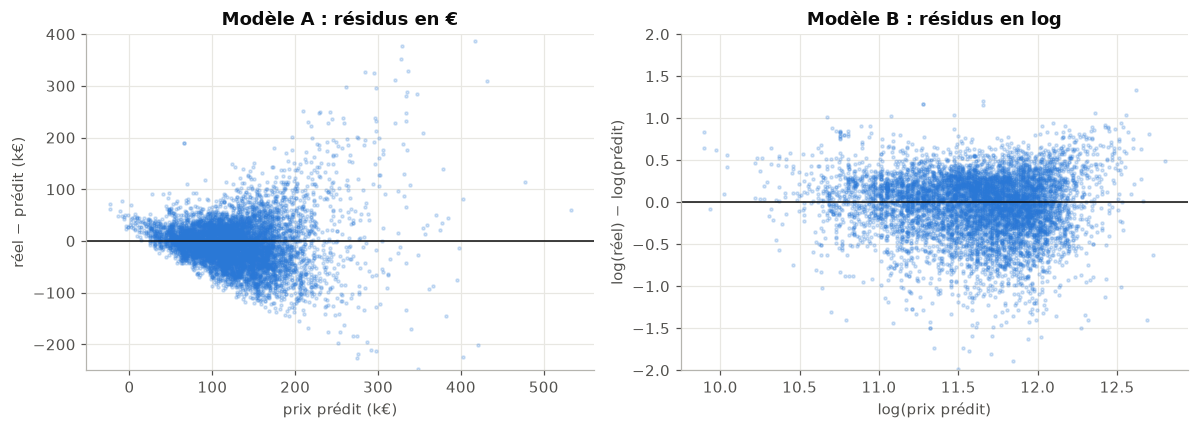

In [6]:
residus_A = test["prix"] - predictions["Modèle A"]
residus_B_log = np.log(test["prix"]) - np.log(predictions["Modèle B"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(predictions["Modèle A"] / 1000, residus_A / 1000, s=4, alpha=0.2, color=BLEU, rasterized=True)
ax1.axhline(0, color="#0b0b0b", linewidth=1)
ax1.set(title="Modèle A : résidus en €", xlabel="prix prédit (k€)", ylabel="réel − prédit (k€)", ylim=(-250, 400))
ax2.scatter(np.log(predictions["Modèle B"]), residus_B_log, s=4, alpha=0.2, color=BLEU, rasterized=True)
ax2.axhline(0, color="#0b0b0b", linewidth=1)
ax2.set(title="Modèle B : résidus en log", xlabel="log(prix prédit)", ylabel="log(réel) − log(prédit)", ylim=(-2, 2))
fig.tight_layout()
plt.show()

À gauche, le modèle sur le prix garde sa forme d'**entonnoir**, et il prédit même quelques **prix négatifs** pour de petites
surfaces dans les départements les moins chers : un modèle additif en euros n'a pas de garde-fou. Avec le log, la prédiction
`exp(...)` est toujours positive. À droite, en log, la largeur du nuage est à peu près
**constante** : l'erreur est désormais proportionnelle au prix, l'hypothèse d'homoscédasticité est bien mieux respectée.

## 5. Modèle C — une variable par commune

Le département est une localisation grossière : Tours et un village d'Indre-et-Loire n'ont pas le même prix au m².
On remplace le département par la **commune** :
- chaque commune avec au moins 10 ventes dans l'apprentissage reçoit sa propre indicatrice ;
- les autres sont regroupées en « autres communes du département ».

In [7]:
communes_gardees = ventes_par_commune[ventes_par_commune >= 10].index


def zone(df):
    return df["code_commune"].where(df["code_commune"].isin(communes_gardees), "autres_" + df["code_departement"])


zones_train = indicatrices(zone(train), "zone").iloc[:, 1:]  # une zone de référence retirée


def variables_communes(df):
    X = variables_base(df).drop(columns="surface")
    X.insert(0, "log_surface", np.log(df["surface"]))
    return X.join(indicatrices(zone(df), "zone", zones_train.columns))


XC_train = variables_communes(train)
XC_test = variables_communes(test)
print(f"{len(communes_gardees)} communes gardées, {XC_train.shape[1]} variables au total")

modele_C = LinearRegression().fit(XC_train, y_train_log)
predictions["Modèle C"] = np.exp(modele_C.predict(XC_test))
resultats.append(evaluer("C : log(prix) + communes", predictions["Modèle C"]))
pd.DataFrame(resultats).set_index("modèle").style.format(
    {"MAE (€)": "{:,.0f}", "RMSE (€)": "{:,.0f}", "R²": "{:.3f}"})

108 communes gardées, 117 variables au total


,MAE (€),RMSE (€),R²
modèle,,,
Baseline : prix au m² de la commune,"31,336","46,523",0.583
Régression simple : prix ~ surface,"38,985","54,938",0.419
A : multiple sur le prix,"34,967","49,687",0.525
B : multiple sur log(prix),"34,102","51,454",0.490
C : log(prix) + communes,"29,212","45,740",0.597


Remarque sur A et B : B a une MAE plus faible, mais un R² plus faible aussi. Le R² en euros est dominé par les grosses erreurs
sur les biens chers, que le modèle en log ne cherche pas à minimiser : il vise l'erreur **relative**.

**Le modèle C bat la baseline par commune** : il combine l'information de localisation fine avec la surface, les pièces,
la dépendance et la tendance annuelle, là où la baseline n'utilise que le prix au m² local.

## 6. Ridge et Lasso : la régularisation aide-t-elle ?

Avec plus de 100 variables, on peut craindre le **sur-apprentissage**. La régularisation ajoute une pénalité sur la taille des coefficients :
- **Ridge** (L2) : pénalité $\alpha \sum \beta_j^2$ → réduit tous les coefficients, sans les annuler ;
- **Lasso** (L1) : pénalité $\alpha \sum |\beta_j|$ → peut mettre des coefficients **exactement à zéro** (sélection de variables).

Les variables sont **standardisées** avant (sinon la pénalité dépendrait de leurs unités).
Le paramètre $\alpha$ est choisi par **validation croisée temporelle** (`TimeSeriesSplit`) : chaque pli apprend
sur le passé et valide sur la période suivante, sans jamais toucher à 2025.

In [8]:
cv_temporelle = TimeSeriesSplit(n_splits=4)

ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 26), cv=cv_temporelle))
ridge.fit(XC_train, y_train_log)
predictions["Ridge"] = np.exp(ridge.predict(XC_test))
resultats.append(evaluer("C + Ridge", predictions["Ridge"]))

lasso = make_pipeline(StandardScaler(), LassoCV(alphas=np.logspace(-4, -1, 13), cv=cv_temporelle, max_iter=20_000))
lasso.fit(XC_train, y_train_log)
predictions["Lasso"] = np.exp(lasso.predict(XC_test))
resultats.append(evaluer("C + Lasso", predictions["Lasso"]))

n_non_nuls = (lasso[-1].coef_ != 0).sum()
print(f"Ridge : alpha choisi = {ridge[-1].alpha_:g}")
print(f"Lasso : alpha choisi = {lasso[-1].alpha_:.5f}, {n_non_nuls} coefficients non nuls sur {XC_train.shape[1]}")

Ridge : alpha choisi = 0.630957
Lasso : alpha choisi = 0.00178, 106 coefficients non nuls sur 117


Pour visualiser l'effet de $\alpha$, on apprend sur 2021-2023 et on mesure l'erreur sur 2024 (validation),
pour une grille de valeurs :

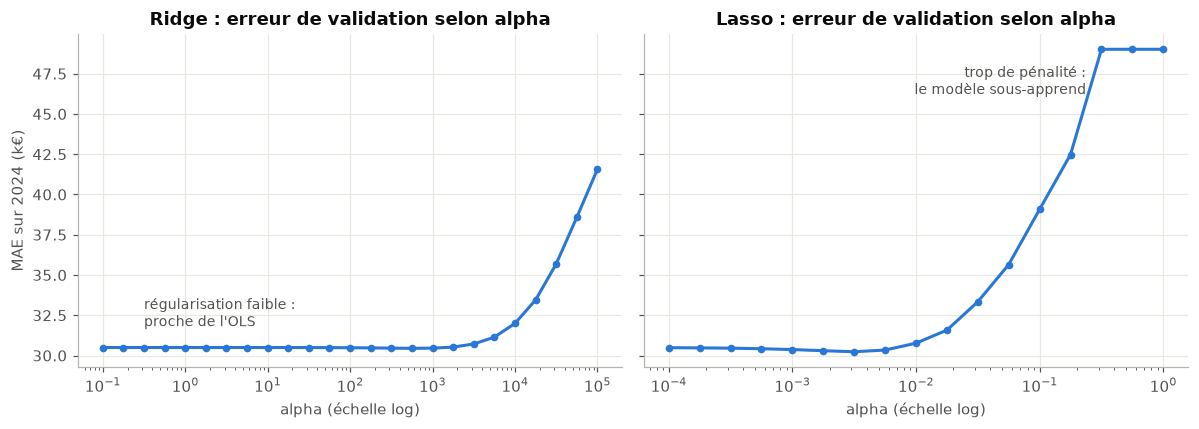

In [9]:
apprentissage = train["annee"] <= 2023
validation = train["annee"] == 2024


def courbe_validation(modele, alphas):
    erreurs = []
    for alpha in alphas:
        pipe = make_pipeline(StandardScaler(), modele(alpha=alpha))
        pipe.fit(XC_train[apprentissage], y_train_log[apprentissage])
        prediction = np.exp(pipe.predict(XC_train[validation]))
        erreurs.append(mean_absolute_error(train.loc[validation, "prix"], prediction))
    return np.array(erreurs)


alphas_ridge = np.logspace(-1, 5, 25)
alphas_lasso = np.logspace(-4, 0, 17)
erreurs_ridge = courbe_validation(Ridge, alphas_ridge)
erreurs_lasso = courbe_validation(lambda alpha: Lasso(alpha=alpha, max_iter=20_000), alphas_lasso)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, alphas, erreurs, nom in [(axes[0], alphas_ridge, erreurs_ridge, "Ridge"),
                                  (axes[1], alphas_lasso, erreurs_lasso, "Lasso")]:
    ax.plot(alphas, erreurs / 1000, color=BLEU, marker="o", markersize=4)
    ax.set_xscale("log")
    ax.set(title=f"{nom} : erreur de validation selon alpha", xlabel="alpha (échelle log)")
axes[0].set_ylabel("MAE sur 2024 (k€)")
axes[0].annotate("régularisation faible :\nproche de l'OLS", (alphas_ridge[2], erreurs_ridge[2] / 1000),
                 xytext=(0, 14), textcoords="offset points", ha="left", color="#52514e", fontsize=9)
axes[1].annotate("trop de pénalité :\nle modèle sous-apprend", (alphas_lasso[-3], erreurs_lasso[-3] / 1000),
                 xytext=(-10, -10), textcoords="offset points", ha="right", va="top", color="#52514e", fontsize=9)
fig.tight_layout()
plt.show()

- La courbe est **plate** pour les petites valeurs de $\alpha$ : la régularisation ne change presque rien.
- Quand $\alpha$ devient grand, l'erreur monte : les coefficients sont trop écrasés, le modèle **sous-apprend**.
- Aucune valeur intermédiaire ne fait nettement mieux que l'OLS.

**Pourquoi ?** Avec environ 32 000 ventes pour un peu plus de 100 variables, l'OLS est déjà stable : il n'y a pas de sur-apprentissage à corriger.
La régularisation devient utile quand il y a beaucoup de variables par rapport au nombre d'observations,
ou des variables très corrélées. C'est un résultat négatif, mais c'est une conclusion en soi.

## 7. Comparaison finale

In [10]:
tableau = pd.DataFrame(resultats).set_index("modèle")
tableau.style.format({"MAE (€)": "{:,.0f}", "RMSE (€)": "{:,.0f}", "R²": "{:.3f}"})

,MAE (€),RMSE (€),R²
modèle,,,
Baseline : prix au m² de la commune,"31,336","46,523",0.583
Régression simple : prix ~ surface,"38,985","54,938",0.419
A : multiple sur le prix,"34,967","49,687",0.525
B : multiple sur log(prix),"34,102","51,454",0.490
C : log(prix) + communes,"29,212","45,740",0.597
C + Ridge,"29,211","45,740",0.597
C + Lasso,"29,237","45,936",0.594


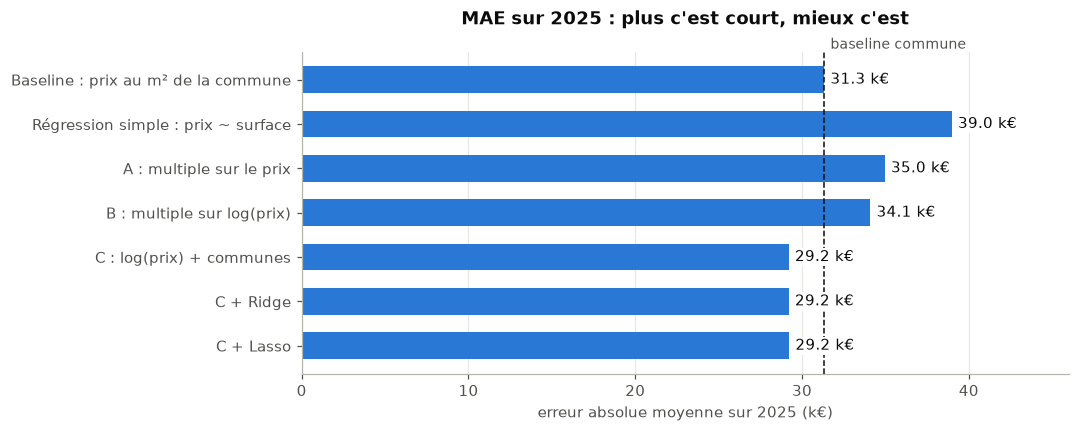

In [11]:
mae = tableau["MAE (€)"][::-1]
fig, ax = plt.subplots(figsize=(9, 3.8))
barres = ax.barh(mae.index, mae.values / 1000, color=BLEU, height=0.6)
etiquettes = ax.bar_label(barres, labels=[f"{v / 1000:.1f} k€" for v in mae.values], padding=4)
for etiquette in etiquettes:
    etiquette.set_bbox(dict(facecolor="white", edgecolor="none", pad=1))
reference = tableau.loc["Baseline : prix au m² de la commune", "MAE (€)"] / 1000
ax.axvline(reference, color="#0b0b0b", linewidth=1, linestyle="--", zorder=1)
ax.annotate("baseline commune", (reference, 1.0), xycoords=("data", "axes fraction"),
            xytext=(4, 2), textcoords="offset points", fontsize=9, color="#52514e")
ax.set_xlabel("erreur absolue moyenne sur 2025 (k€)")
ax.set_title("MAE sur 2025 : plus c'est court, mieux c'est", pad=18)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, mae.max() / 1000 * 1.18)
plt.show()

In [12]:
noms_dep = {"18": "Cher", "28": "Eure-et-Loir", "36": "Indre",
            "37": "Indre-et-Loire", "41": "Loir-et-Cher", "45": "Loiret"}
departement = test["code_departement"].map(noms_dep)
ecart = pd.DataFrame({
    "régression simple": (test["prix"] / predictions["Régression simple"] - 1).groupby(departement).median(),
    "modèle C": (test["prix"] / predictions["Modèle C"] - 1).groupby(departement).median(),
})
ecart.style.format("{:+.0%}").set_caption("Écart médian entre prix réel et prix prédit, par département")

,régression simple,modèle C
code_departement,,
Cher,-32%,+8%
Eure-et-Loir,-3%,-1%
Indre,-44%,+5%
Indre-et-Loire,+20%,-2%
Loir-et-Cher,-19%,+3%
Loiret,+1%,-2%


Le **biais géographique** de la régression simple (−44 % dans l'Indre, +20 % en Indre-et-Loire) est **presque effacé** avec le modèle C :
les écarts médians ne dépassent plus ±8 %.

## 8. Conclusions

| Étape | Ce qu'elle apporte |
|---|---|
| Régression multiple (A) | la localisation et les pièces réduisent l'erreur par rapport à la régression simple |
| VIF | colinéarité modérée surface / pièces (VIF ≈ 4) : coefficients interprétables « à surface égale » |
| Log du prix (B) | effets en %, résidus homogènes (fin de l'hétéroscédasticité) |
| Communes (C) | **meilleur modèle : il bat la baseline par commune** et supprime le biais géographique |
| Ridge / Lasso | pas de gain : avec 32 000 ventes pour ~120 variables, l'OLS ne sur-apprend pas |

**Limites** :
- l'erreur reste d'environ 29 000 € en moyenne : DVF ne contient ni l'état du bien, ni l'étage, ni le DPE, ni le quartier précis ;
- un modèle linéaire ne capte pas les effets non linéaires de la position GPS (quartiers) : des arbres de décision ou du
  *gradient boosting* seraient la suite logique.

**Prochaine étape** : une application Streamlit qui estime le prix d'un appartement avec le modèle C.